# 30 Linear Regression Programs for Data Science
This notebook contains 30 implementations of Linear Regression concepts ranging from math from scratch, Scikit-Learn pipelines, statistical diagnostics, robust variants, to PyTorch/TensorFlow implementations.

## 1. Fundamentals & Math From Scratch

### 1. Simple Linear Regression from Scratch (Pure Python)

In [1]:
x = [1, 2, 3, 4, 5]
y = [2, 4, 5, 4, 5]

n = len(x)
mean_x, mean_y = sum(x) / n, sum(y) / n
num = sum((x[i] - mean_x) * (y[i] - mean_y) for i in range(n))
den = sum((x[i] - mean_x) ** 2 for i in range(n))

m = num / den
c = mean_y - m * mean_x
print(f"y = {m:.2f}x + {c:.2f}")

y = 0.60x + 2.20


### 2. Vectorized Ordinary Least Squares (NumPy Matrix Form)

In [2]:
import numpy as np

X = np.array([[1, 1], [1, 2], [1, 3], [1, 4]])
y = np.array([2, 3, 5, 7])
beta = np.linalg.inv(X.T @ X) @ X.T @ y
print("Coefficients:", beta)

Coefficients: [0.  1.7]


### 3. Simple Gradient Descent Implementation

In [3]:
import numpy as np

X = np.array([1, 2, 3, 4, 5])
y = np.array([2, 4, 5, 4, 5])
w, b, lr, epochs = 0.0, 0.0, 0.01, 1000

for _ in range(epochs):
    y_pred = w * X + b
    dw = -2 * np.mean(X * (y - y_pred))
    db = -2 * np.mean(y - y_pred)
    w -= lr * dw
    b -= lr * db

print(f"Weight: {w:.2f}, Bias: {b:.2f}")

Weight: 0.62, Bias: 2.14


### 4. Stochastic Gradient Descent (SGD) Implementation

In [4]:
import numpy as np

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([2, 4, 5, 4, 5])
w, b, lr = 0.0, 0.0, 0.01

for epoch in range(100):
    for i in range(len(X)):
        y_pred = w * X[i] + b
        w -= lr * (-2 * X[i] * (y[i] - y_pred))
        b -= lr * (-2 * (y[i] - y_pred))

print(f"SGD Weight: {w[0]:.2f}, Bias: {b[0]:.2f}")

SGD Weight: 0.63, Bias: 1.95


## 2. Scikit-Learn Implementation & Evaluation

### 5. Basic Scikit-Learn Fit and Predict

In [5]:
from sklearn.linear_model import LinearRegression
import numpy as np

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([2, 4, 5, 4, 5])

model = LinearRegression().fit(X, y)
print("Predictions:", model.predict([[6], [7]]))

Predictions: [5.8 6.4]


### 6. Model Evaluation Metrics (MSE, RMSE, MAE, R²)

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

y_true = np.array([3, -0.5, 2, 7])
y_pred = np.array([2.5, 0.0, 2, 8])

print("MAE:", mean_absolute_error(y_true, y_pred))
print("MSE:", mean_squared_error(y_true, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
print("R2 Score:", r2_score(y_true, y_pred))

MAE: 0.5
MSE: 0.375
RMSE: 0.6123724356957945
R2 Score: 0.9486081370449679


### 7. Adjusted R-Squared Calculation

In [7]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("Adjusted R2:", adjusted_r2(0.85, n=100, p=5))

Adjusted R2: 0.8420212765957447


### 8. Train-Test Split Workflow

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

X = np.random.rand(100, 3)
y = X @ np.array([1.5, -2, 3]) + 0.5

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
print("Test R2:", model.score(X_test, y_test))

Test R2: 1.0


### 9. K-Fold Cross-Validation

In [9]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
import numpy as np

X, y = np.random.rand(100, 2), np.random.rand(100)
scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print("Mean CV R2:", np.mean(scores))

Mean CV R2: -0.03871731557407976


## 3. Data Preprocessing & Pipeline Integration

### 10. Handling Categorical Variables (One-Hot Encoding)

In [10]:
import pandas as pd
from sklearn.linear_model import LinearRegression

df = pd.DataFrame({'Size': [1000, 1500, 1200], 'City': ['NY', 'LA', 'NY'], 'Price': [500, 400, 550]})
df_encoded = pd.get_dummies(df, columns=['City'], drop_first=True)

X = df_encoded.drop('Price', axis=1)
y = df_encoded['Price']
model = LinearRegression().fit(X, y)
print("Coefficients:", model.coef_)

Coefficients: [  0.25 225.  ]


### 11. Feature Scaling Impact (StandardScaler)

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
import numpy as np

X = np.array([[1000, 2], [1500, 3], [800, 1]])
y = np.array([300, 450, 200])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = SGDRegressor().fit(X_scaled, y)
print("Model score on scaled data:", model.score(X_scaled, y))

Model score on scaled data: 0.9997864287279878


/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/sklearn/linear_model/_stochastic_gradient.py:1620: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


### 12. Polynomial Regression Transformation

In [12]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import numpy as np

X = np.array([[1], [2], [3], [4]])
y = np.array([1, 4, 9, 16])

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

model = LinearRegression().fit(X_poly, y)
print("Coefficients:", model.coef_)

Coefficients: [ 0.00000000e+00 -7.49514384e-15  1.00000000e+00]


### 13. Full Pipeline Assembly

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
import numpy as np

X = np.random.rand(50, 2)
y = np.random.rand(50)

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2)),
    ('model', Ridge(alpha=1.0))
])

pipeline.fit(X, y)
print("Pipeline Score:", pipeline.score(X, y))

Pipeline Score: 0.26746785504362836


## 4. Regularization Variants

### 14. Ridge Regression (L2 Penalty)

In [14]:
from sklearn.linear_model import Ridge
import numpy as np

X = np.random.rand(50, 10)
y = np.random.rand(50)

ridge = Ridge(alpha=10.0).fit(X, y)
print("Ridge Coefficients:", ridge.coef_)

Ridge Coefficients: [ 0.02251754 -0.07944045 -0.00743107  0.02950769  0.02421373  0.00474994
  0.03107762 -0.04202666 -0.0132614   0.00026932]


### 15. Lasso Regression (L1 Feature Selection)

In [15]:
from sklearn.linear_model import Lasso
import numpy as np

X = np.random.rand(50, 10)
y = X[:, 0] * 3 + np.random.randn(50) * 0.1

lasso = Lasso(alpha=0.1).fit(X, y)
print("Non-zero feature indices:", np.where(lasso.coef_ != 0)[0])

Non-zero feature indices: [0]


### 16. ElasticNet Combination

In [16]:
from sklearn.linear_model import ElasticNet
import numpy as np

X = np.random.rand(50, 5)
y = np.random.rand(50)

elastic = ElasticNet(alpha=0.1, l1_ratio=0.5).fit(X, y)
print("ElasticNet Coefficients:", elastic.coef_)

ElasticNet Coefficients: [0. 0. 0. 0. 0.]


### 17. RidgeCV Hyperparameter Tuning

In [17]:
from sklearn.linear_model import RidgeCV
import numpy as np

X, y = np.random.rand(100, 5), np.random.rand(100)
model = RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0], cv=5).fit(X, y)
print("Optimal Alpha:", model.alpha_)

Optimal Alpha: 10.0


## 5. Diagnostics & Statistical Inference

### 18. Statsmodels OLS Diagnostic Summary

In [18]:
import statsmodels.api as sm
import numpy as np

X = np.random.rand(100, 2)
X = sm.add_constant(X)
y = np.random.rand(100)

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                 -0.003
Method:                 Least Squares   F-statistic:                    0.8330
Date:                Thu, 10 Sep 2026   Prob (F-statistic):              0.438
Time:                        21:42:55   Log-Likelihood:                -15.672
No. Observations:                 100   AIC:                             37.34
Df Residuals:                      97   BIC:                             45.16
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4975      0.074      6.687      0.0

### 19. Multicollinearity Assessment via VIF

In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

df = pd.DataFrame({'X1': [1, 2, 3, 4], 'X2': [2, 4, 6, 8], 'X3': [1, 5, 2, 8]})
vif_data = pd.DataFrame({
    "Feature": df.columns,
    "VIF": [variance_inflation_factor(df.values, i) for i in range(df.shape[1])]
})
print(vif_data)

  Feature           VIF
0      X1  1.000800e+15
1      X2  1.000800e+15
2      X3  2.173913e+00


/var/folders/m3/d20plx6j78j8bn1tpj33q_5c0000gn/T/ipykernel_11328/1567947622.py:7: UserWarning: The design matrix is poorly conditioned (condition number=8.99e+15). VIF calculations may be numerically unstable.
  "VIF": [variance_inflation_factor(df.values, i) for i in range(df.shape[1])]
/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


### 20. Residual Analysis & Normality Test

In [20]:
import scipy.stats as stats
import numpy as np

residuals = np.random.normal(0, 1, 100)
stat, p_val = stats.shapiro(residuals)
print("Shapiro-Wilk p-value:", p_val)

Shapiro-Wilk p-value: 0.14080137968877288


### 21. Detecting Heteroscedasticity (Breusch-Pagan)

In [21]:
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm
import numpy as np

X = sm.add_constant(np.random.rand(100, 2))
y = np.random.rand(100)
model = sm.OLS(y, X).fit()

lm_stat, p_val, _, _ = het_breuschpagan(model.resid, model.model.exog)
print("Breusch-Pagan p-value:", p_val)

Breusch-Pagan p-value: 0.7706198326127973


### 22. Identifying Outliers with Cook's Distance

In [22]:
import statsmodels.api as sm
import numpy as np

X = sm.add_constant(np.random.rand(50, 2))
y = np.random.rand(50)
model = sm.OLS(y, X).fit()

influence = model.get_influence()
cooks_d = influence.cooks_distance[0]
print("Top Outlier Index:", np.argmax(cooks_d))

Top Outlier Index: 7


## 6. Advanced Regressors & Robust Variants

### 23. Huber Robust Regression (Outlier Resilience)

In [23]:
from sklearn.linear_model import HuberRegressor
import numpy as np

X = np.expand_dims(np.linspace(0, 10, 50), 1)
y = 2 * X.squeeze() + np.random.randn(50)
y[0], y[1] = 100, -100  # Extreme Outliers

huber = HuberRegressor().fit(X, y)
print("Robust Slope:", huber.coef_)

Robust Slope: [1.96114363]


### 24. RANSAC Outlier Rejection

In [24]:
from sklearn.linear_model import RANSACRegressor, LinearRegression
import numpy as np

X = np.random.rand(100, 1)
y = 3 * X.squeeze() + np.random.randn(100) * 0.2

ransac = RANSACRegressor(estimator=LinearRegression()).fit(X, y)
print("Inlier mask sum:", np.sum(ransac.inlier_mask_))

Inlier mask sum: 100


### 25. Quantile Regression

In [25]:
from sklearn.linear_model import QuantileRegressor
import numpy as np

X, y = np.random.rand(100, 1), np.random.rand(100)
median_model = QuantileRegressor(quantile=0.5, alpha=0).fit(X, y)
print("Median Regressor Coefficients:", median_model.coef_)

Median Regressor Coefficients: [-0.08837165]


### 26. Generalized Least Squares (GLS) for Autocorrelation

In [26]:
import statsmodels.api as sm
import numpy as np

X = sm.add_constant(np.random.rand(100, 2))
y = np.random.rand(100)
gls_model = sm.GLS(y, X).fit()
print("GLS Params:", gls_model.params)

GLS Params: [ 0.38969005  0.23120426 -0.07275908]


## 7. Special Techniques & Deep Learning

### 27. Logarithmic Target Transformation

In [27]:
import numpy as np
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4]])
y = np.array([10, 100, 1000, 10000])

y_log = np.log(y)
model = LinearRegression().fit(X, y_log)
pred = np.exp(model.predict([[5]]))
print("Transformed Prediction:", pred)

Transformed Prediction: [100000.]


### 28. Linear Regression using PyTorch Autograd

In [28]:
import torch

X = torch.tensor([[1.0], [2.0], [3.0]], requires_grad=False)
y = torch.tensor([[2.0], [4.0], [6.0]], requires_grad=False)

w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)

optimizer = torch.optim.SGD([w, b], lr=0.01)

for epoch in range(100):
    pred = X @ w + b
    loss = torch.mean((pred - y) ** 2)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"PyTorch Weights: w={w.item():.2f}, b={b.item():.2f}")

PyTorch Weights: w=1.81, b=-0.11


### 29. Linear Regression using TensorFlow / Keras

In [29]:
import tensorflow as tf
import numpy as np

X = np.array([1.0, 2.0, 3.0, 4.0])
y = np.array([2.0, 4.0, 6.0, 8.0])

model = tf.keras.Sequential([tf.keras.layers.Dense(units=1, input_shape=[1])])
model.compile(optimizer='sgd', loss='mean_squared_error')
model.fit(X, y, epochs=100, verbose=0)
print("TF Prediction for 5:", model.predict(np.array([5.0])))

/Users/rio/top mentor/Project/Assignment_projects/30_Linear_Regression_Programs/venv312/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
TF Prediction for 5: [[9.833206]]


### 30. Feature Importance Plotting

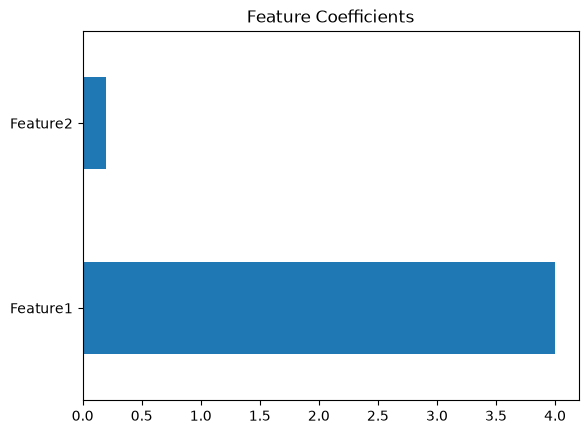

In [30]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import pandas as pd

X = pd.DataFrame({'Feature1': [1,2,3,4], 'Feature2': [10,20,15,25]})
y = [5, 11, 14, 20]

model = LinearRegression().fit(X, y)
importance = pd.Series(model.coef_, index=X.columns)
importance.plot(kind='barh')
plt.title("Feature Coefficients")
plt.show()